# Produksi agregat

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> 34 provinsi, 2017–2025.
--> Tenaga kerja 2025 menyalin 2024. Output dan investasi 2025 teramati.
--> Residual pada bagian ini adalah residual akuntansi agregat.
--> Investasi adalah arus PMTB riil.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NAVY, TEAL, GRAY, CREAM, INK, PAPER = (
    "#0E2440", "#46A694", "#797F8C", "#F2E6CE", "#081526", "#FFFFFF",
)
GRID = "#EEF0F3"
B1, B2 = 0.3874222, 0.1928021
ISLAND_INK = {
    "Sumatera": "#8A6A32", "Jawa": "#9D2459", "Bali-Nusra": "#D9042B",
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": "#1F6F66",
}
ISLANDS = ["Sumatera", "Jawa", "Bali-Nusra", "Kalimantan", "Sulawesi", "Maluku-Papua"]
SECTORS = [
    ("A", "Pertanian", CREAM),
    ("B", "Pertambangan", "#D9042B"),
    ("C", "Industri pengolahan", NAVY),
    ("DEF", "Utilitas dan konstruksi", TEAL),
    ("JASA", "Jasa", "#5DD0E6"),
]
LETTERS = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]
DEF = ["D", "E", "F"]
JASA = ["G", "H", "I", "J", "K", "L", "MN", "O", "P", "Q", "RSTU"]


def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "02 Code" / "BKPM" / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")


ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "revisi_53_61"
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "axes.unicode_minus": False, "axes.titlecolor": NAVY, "text.color": NAVY,
    "axes.labelcolor": NAVY, "xtick.color": GRAY, "ytick.color": NAVY,
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
})


def clean(ax, grid="y"):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#E2E5EA")
    ax.spines["bottom"].set_color("#E2E5EA")
    ax.tick_params(length=0)
    if grid:
        ax.set_axisbelow(True)
        ax.grid(True, axis=grid, color=GRID, lw=0.8)


def head(fig, title, subtitle, top=0.88):
    """Store the header; position it after the final subplot layout."""
    fig._report_header = (title, subtitle)
    fig.tight_layout(rect=(0, 0, 1, top))


def _finish_header(fig):
    """Wrap and separate text using rendered sizes, independent of figure height."""
    for artist in getattr(fig, "_report_header_artists", []):
        artist.remove()
    fig._report_header_artists = []
    if not hasattr(fig, "_report_header"):
        return
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    dpi = fig.dpi
    height_px = fig.bbox.height
    width_px = fig.bbox.width * 0.96
    bounds = [ax.get_tightbbox(renderer) for ax in fig.axes if ax.get_visible()]
    bounds += [a.get_window_extent(renderer) for a in fig.legends + fig.texts
               if a.get_visible()]
    content_top = max((b.y1 for b in bounds if b is not None), default=height_px * .9)

    def wrapped(text, size):
        probe = fig.text(0, 0, "", fontsize=size)
        lines = []
        for paragraph in str(text).split("\n"):
            line = ""
            for word in paragraph.split():
                trial = (line + " " + word).strip()
                probe.set_text(trial)
                if line and probe.get_window_extent(renderer).width > width_px:
                    lines.append(line)
                    line = word
                else:
                    line = trial
            lines.append(line)
        probe.remove()
        return "\n".join(lines)

    title, subtitle = fig._report_header
    gap = 10 * dpi / 72
    sub = fig.text(.01, (content_top + gap) / height_px,
                   wrapped(subtitle, 11), ha="left", va="bottom",
                   fontsize=11, color=GRAY, linespacing=1.35)
    fig.canvas.draw()
    sub_box = sub.get_window_extent(fig.canvas.get_renderer())
    main = fig.text(.01, (sub_box.y1 + gap) / height_px,
                    wrapped(title, 16), ha="left", va="bottom",
                    fontsize=16, color=NAVY, fontweight="medium", linespacing=1.25)
    fig._report_header_artists = [main, sub]
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    assert main.get_window_extent(renderer).y0 > sub.get_window_extent(renderer).y1
    assert sub.get_window_extent(renderer).y0 > content_top


def _spread(ys, gap):
    order = sorted(range(len(ys)), key=lambda i: ys[i])
    out = [None] * len(ys)
    floor = None
    for i in order:
        y = ys[i] if floor is None else max(ys[i], floor + gap)
        out[i] = y
        floor = y
    return out


def save(fig, name):
    _finish_header(fig)
    fig.savefig(OUT / name, dpi=180, bbox_inches="tight", facecolor=PAPER)
    print(name)
    plt.show()


In [2]:
tfp = pd.read_excel(ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx")
pulau = pd.read_csv(ROOT / "01 Data/BKPM/processed/Dataset Provinsi(prov_name).csv")
pulau = pulau.dropna(subset=["Code_Prov"]).drop_duplicates("Code_Prov")
pulau["Code_Prov"] = pulau.Code_Prov.astype(int)
tfp = tfp.merge(pulau[["Code_Prov", "Pulau"]], on="Code_Prov", how="left")
tfp["Pre_Prov"] = tfp.Pre_Prov.replace({"DI yogyakarta": "DI Yogyakarta"})
assert tfp.Pulau.notna().all()

nat = tfp.groupby("Year", as_index=False)[["pdrb_adhk", "pmtb_adhk", "labours_total"]].sum()
base = nat.loc[nat.Year == 2017].iloc[0]
for col, src in [("idx_y", "pdrb_adhk"), ("idx_i", "pmtb_adhk"), ("idx_l", "labours_total")]:
    nat[col] = 100 * nat[src] / base[src]
nat["idx_yl"] = 100 * (nat.pdrb_adhk / nat.labours_total) / (base.pdrb_adhk / base.labours_total)
nat["idx_il"] = 100 * (nat.pmtb_adhk / nat.labours_total) / (base.pmtb_adhk / base.labours_total)
g = nat.copy()
g["g_y"] = 100 * np.log(g.pdrb_adhk).diff()
g["k_i"] = B1 * 100 * np.log(g.pmtb_adhk).diff()
g["k_l"] = B2 * 100 * np.log(g.labours_total).diff()
g["resid"] = g.g_y - g.k_i - g.k_l
ann = g.dropna(subset=["g_y"]).copy()
ann["resid_since"] = ann.resid.cumsum()


## Teks utama


### Gambar 1. Output, investasi, dan tenaga kerja


01_indeks_agregat.png


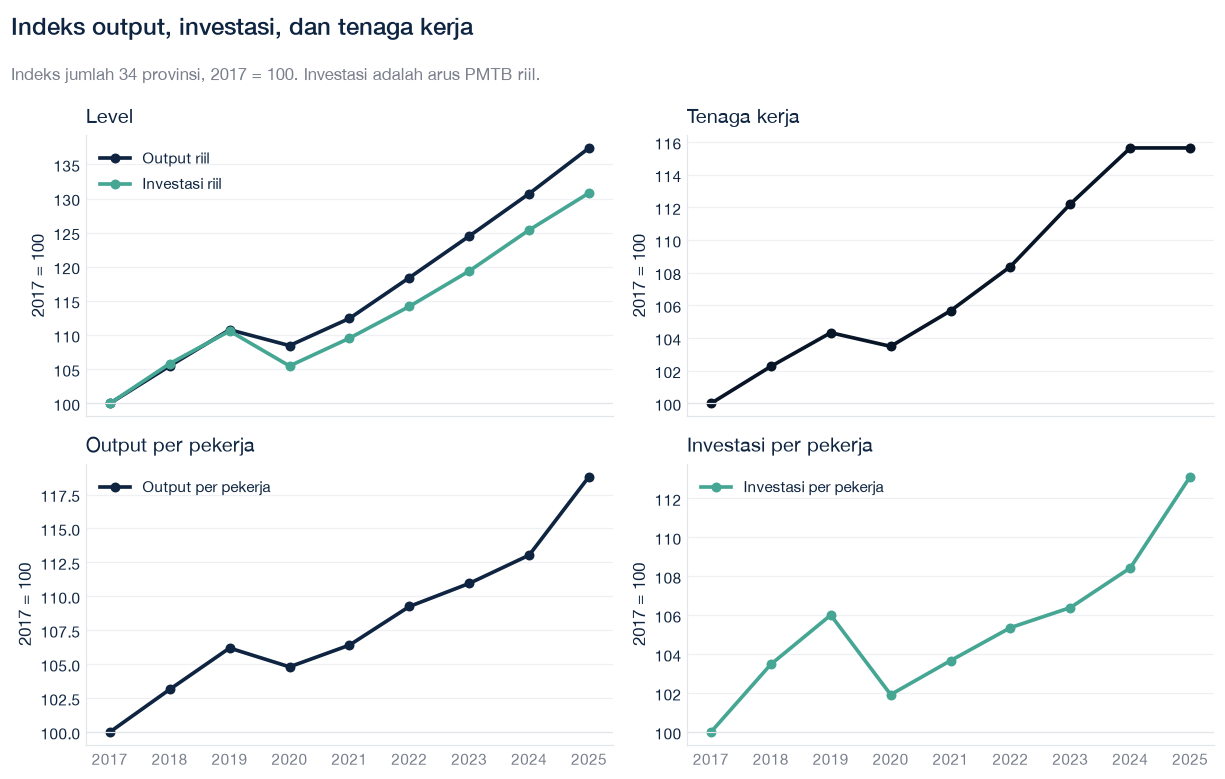

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(11.2, 7.2), sharex=True)
panels = [
    (axes[0, 0], [("idx_y", "Output riil", NAVY), ("idx_i", "Investasi riil", TEAL)], "Level"),
    (axes[0, 1], [("idx_l", "Tenaga kerja", INK)], "Tenaga kerja"),
    (axes[1, 0], [("idx_yl", "Output per pekerja", NAVY)], "Output per pekerja"),
    (axes[1, 1], [("idx_il", "Investasi per pekerja", TEAL)], "Investasi per pekerja"),
]
for ax, series, title in panels:
    for col, lab, color in series:
        ax.plot(nat.Year, nat[col], color=color, lw=2.4, marker="o", ms=5.5, label=lab)
    ax.axhline(100, color="#E2E5EA", lw=0.8)
    ax.set_title(title, loc="left", fontsize=13, pad=8)
    ax.set_ylabel("2017 = 100")
    clean(ax)
    ax.set_xticks(range(2017, 2026))
    if len(series) > 1 or series[0][0] != "idx_l":
        ax.legend(frameon=False, fontsize=10, loc="upper left")
head(fig, "Indeks output, investasi, dan tenaga kerja",
     "Indeks jumlah 34 provinsi, 2017 = 100. Investasi adalah arus PMTB riil.")
save(fig, "01_indeks_agregat.png")


--> Indeks dihitung dari jumlah level 34 provinsi.
--> Rasio per pekerja memakai jumlah level.
--> Investasi per pekerja adalah arus PMTB riil per pekerja.


### Gambar 2. Akuntansi pertumbuhan


01_viz_deskriptif.ipynb:1:63: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
02_akuntansi_pertumbuhan.png


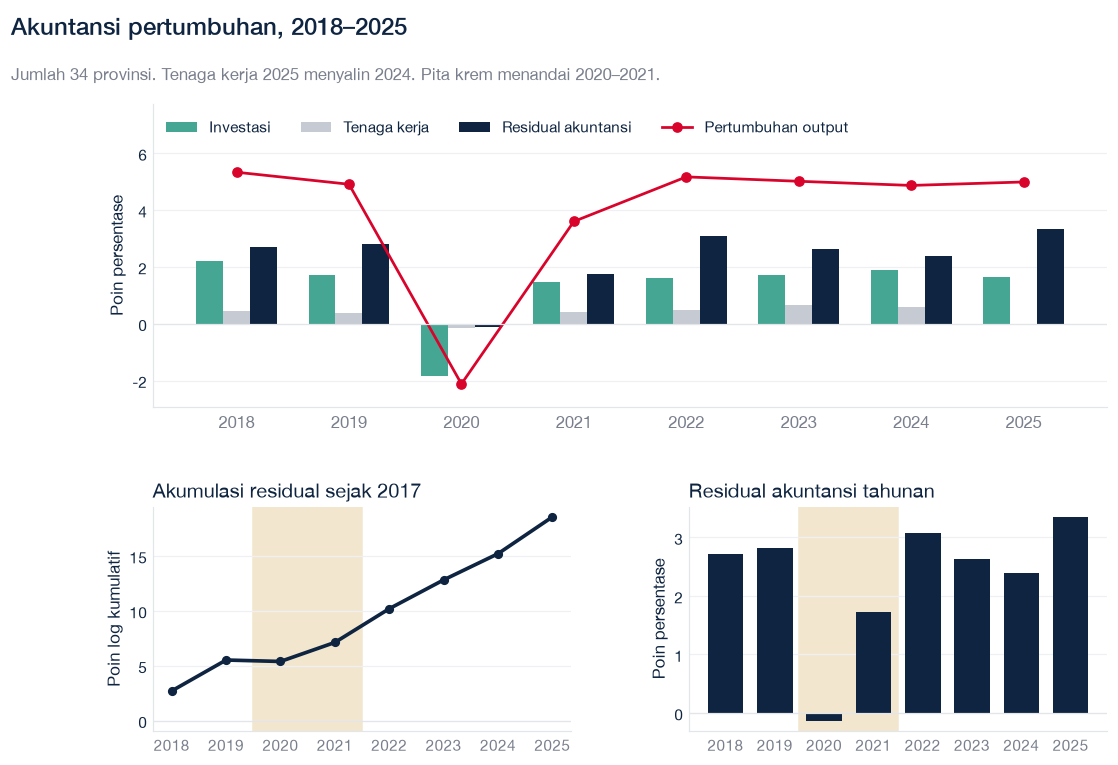

In [4]:
fig = plt.figure(figsize=(11.2, 7.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1.35, 1], hspace=0.38, wspace=0.28)
ax = fig.add_subplot(gs[0, :])
x = np.arange(len(ann))
w = 0.24
b1 = ax.bar(x - w, ann.k_i, width=w, color=TEAL, label="Investasi")
b2 = ax.bar(x, ann.k_l, width=w, color="#C5CAD3", label="Tenaga kerja")
b3 = ax.bar(x + w, ann.resid, width=w, color=NAVY, label="Residual akuntansi")
ln, = ax.plot(x, ann.g_y, color="#D9042B", marker="o", ms=6, lw=1.8, label="Pertumbuhan output")
ax.axhline(0, color="#E2E5EA", lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(ann.Year.astype(int), fontsize=11)
ax.set_ylabel("Poin persentase")
clean(ax)
ax.legend(handles=[b1, b2, b3, ln], ncol=4, frameon=False, fontsize=10, loc="upper left")
ax.set_ylim(ann[["k_i", "k_l", "resid", "g_y"]].min().min() - 0.8, ann.g_y.max() + 2.4)

ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[1, 1])
ax2.plot(ann.Year, ann.resid_since, color=NAVY, lw=2.4, marker="o", ms=5)
ax2.axhline(0, color="#E2E5EA", lw=0.8)
ax2.set_title("Akumulasi residual sejak 2017", loc="left", fontsize=13)
ax2.set_ylabel("Poin log kumulatif")
ax3.bar(ann.Year, ann.resid, color=NAVY, width=0.72)
ax3.axhline(0, color="#E2E5EA", lw=0.8)
ax3.set_title("Residual akuntansi tahunan", loc="left", fontsize=13)
ax3.set_ylabel("Poin persentase")
for a in (ax2, ax3):
    a.axvspan(2019.5, 2021.5, color=CREAM, zorder=0)
    clean(a)
    a.set_xticks(range(2018, 2026))
head(fig, "Akuntansi pertumbuhan, 2018–2025",
     "Jumlah 34 provinsi. Tenaga kerja 2025 menyalin 2024. Pita krem menandai 2020–2021.", top=0.84)
save(fig, "02_akuntansi_pertumbuhan.png")


--> Kontribusi investasi = 0,387 × pertumbuhan PMTB riil.
--> Kontribusi tenaga kerja = 0,193 × pertumbuhan jumlah pekerja.
--> Pita krem adalah 2020–2021.
--> Residual akuntansi adalah selisihnya terhadap pertumbuhan output.


### Gambar 3. Jalur wilayah


03_jalur_wilayah.png


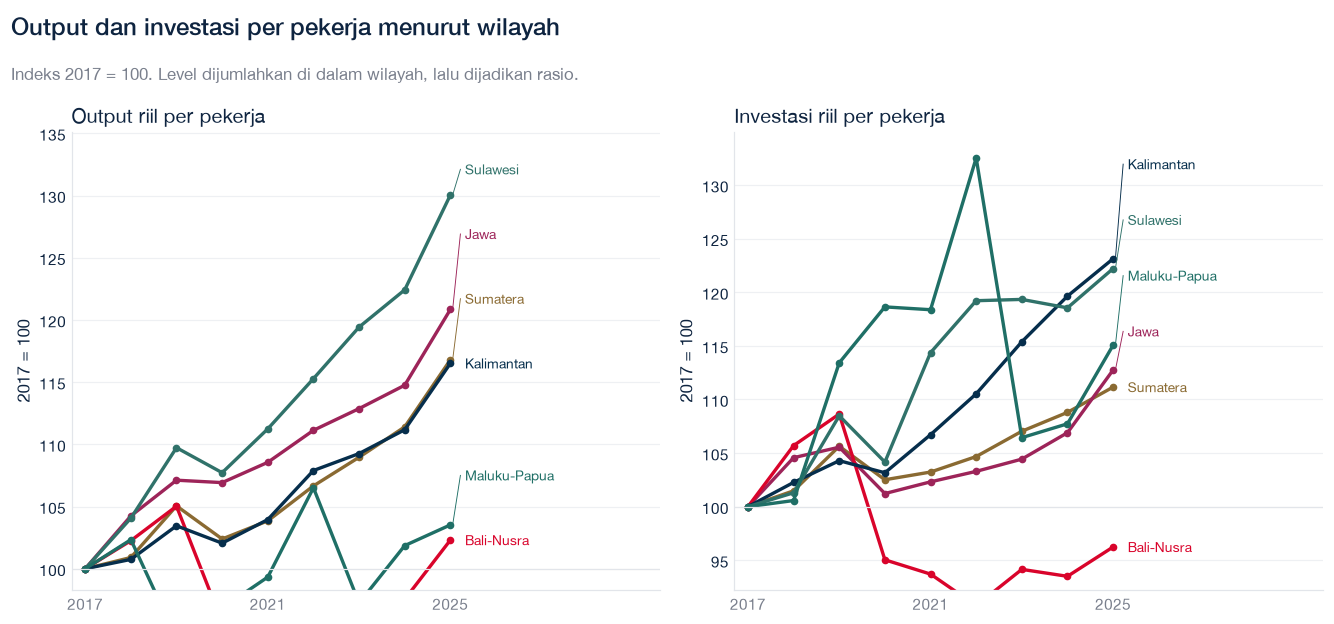

In [5]:
island = tfp.groupby(["Pulau", "Year"], as_index=False)[["pdrb_adhk", "labours_total", "pmtb_adhk"]].sum()
island["yl"] = island.pdrb_adhk / island.labours_total
island["il"] = island.pmtb_adhk / island.labours_total
b0 = island.loc[island.Year == 2017, ["Pulau", "yl", "il"]].rename(columns={"yl": "yl0", "il": "il0"})
island = island.merge(b0, on="Pulau")
island["idx_yl"] = 100 * island.yl / island.yl0
island["idx_il"] = 100 * island.il / island.il0

fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.6), sharex=True)
for ax, col, title in zip(axes, ["idx_yl", "idx_il"], ["Output riil per pekerja", "Investasi riil per pekerja"]):
    for pulau in ISLANDS:
        sub = island.loc[island.Pulau == pulau].sort_values("Year")
        color = ISLAND_INK[pulau]
        ax.plot(sub.Year, sub[col], color=color, lw=2.2, marker="o", ms=4)
    ends = []
    for pulau in ISLANDS:
        sub = island.loc[island.Pulau == pulau].sort_values("Year")
        ends.append((sub[col].iloc[-1], pulau, ISLAND_INK[pulau]))
    gap = 5.2
    raw = [y for y, _, _ in ends]
    placed = _spread(raw, gap)
    for (y0, pulau, color), y in zip(ends, placed):
        if abs(y - y0) > 0.6:
            ax.plot([2025.05, 2025.22], [y0, y], color=color, lw=0.6, clip_on=False)
        ax.text(2025.32, y, pulau, color=color, fontsize=9, va="center", clip_on=False)
    ax.axhline(100, color="#E2E5EA", lw=0.8)
    ax.set_xlim(2016.7, 2029.6)
    ax.set_ylim(min(raw) - 4, max(max(raw), max(placed)) + 3)
    ax.set_title(title, loc="left", fontsize=13)
    ax.set_ylabel("2017 = 100")
    clean(ax)
    ax.set_xticks([2017, 2021, 2025])
head(fig, "Output dan investasi per pekerja menurut wilayah",
     "Indeks 2017 = 100. Level dijumlahkan di dalam wilayah, lalu dijadikan rasio.")
save(fig, "03_jalur_wilayah.png")


--> Nama wilayah diletakkan pada nilai 2025.
--> Setiap garis adalah jumlah provinsi di wilayah itu.


### Gambar 4. Komposisi sektoral wilayah


04_komposisi_wilayah.png


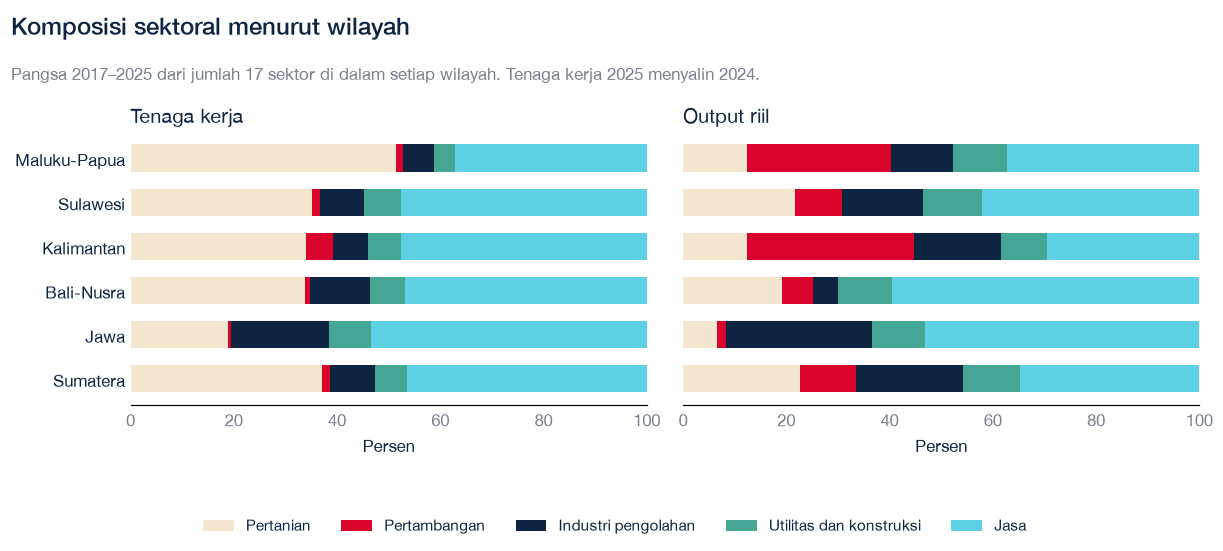

In [6]:
src = pd.read_excel(
    ROOT / "01 Data/TFP/output/konstruksi/TFP Provinsi 2017-2025.xlsx",
    sheet_name="sektor",
)
src = src.loc[src.Year.between(2017, 2025)].copy()
src["Pre_Prov"] = src.Pre_Prov.replace({"DI yogyakarta": "DI Yogyakarta"})
src = src.merge(tfp[["Code_Prov", "Pulau"]].drop_duplicates(), on="Code_Prov", how="left")
tk = {s: f"{s}_TenagaKerja" for s in LETTERS}
yk = {s: f"{s}_ADHK" for s in LETTERS}


def shares_from_levels(frame, cols):
    levels = pd.DataFrame({
        "A": frame[cols["A"]],
        "B": frame[cols["B"]],
        "C": frame[cols["C"]],
        "DEF": frame[[cols[s] for s in DEF]].sum(axis=1),
        "JASA": frame[[cols[s] for s in JASA]].sum(axis=1),
    })
    return levels.div(levels.sum(axis=1), axis=0)


def stacked(ax, frame, prefix, title):
    left = np.zeros(len(frame))
    y = np.arange(len(frame))
    for key, lab, color in SECTORS:
        val = 100 * frame[f"{prefix}{key}"].to_numpy()
        ax.barh(y, val, left=left, color=color, height=0.62, label=lab)
        left = left + val
    ax.set_yticks(y)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Persen")
    ax.set_title(title, loc="left", fontsize=13)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(length=0, labelsize=11)
    ax.invert_yaxis()


tk_sum = src.groupby("Pulau")[list(tk.values())].sum()
y_sum = src.groupby("Pulau")[list(yk.values())].sum()
isle = pd.concat([
    shares_from_levels(tk_sum.reset_index(), tk).add_prefix("tk_"),
    shares_from_levels(y_sum.reset_index(), yk).add_prefix("y_"),
], axis=1)
isle.insert(0, "Pulau", tk_sum.index)
isle["ord"] = isle.Pulau.map({p: i for i, p in enumerate(ISLANDS)})
isle = isle.sort_values("ord")

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.6), sharey=True)
stacked(axes[0], isle, "tk_", "Tenaga kerja")
stacked(axes[1], isle, "y_", "Output riil")
axes[0].set_yticklabels(isle.Pulau)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, 0.02))
head(fig, "Komposisi sektoral menurut wilayah",
     "Pangsa 2017–2025 dari jumlah 17 sektor di dalam setiap wilayah. Tenaga kerja 2025 menyalin 2024.", top=0.84)
fig.tight_layout(rect=(0, 0.08, 1, 0.84))
save(fig, "04_komposisi_wilayah.png")


--> Pangsa dihitung dari jumlah level sektoral, lalu dibagi jumlah 17 sektor.
--> Pertanian, pertambangan, dan industri pengolahan dipisah.
--> Nol tercatat pada beberapa sel tenaga kerja tetap masuk penyebut.


## Lampiran


A1_komposisi_34_provinsi.png


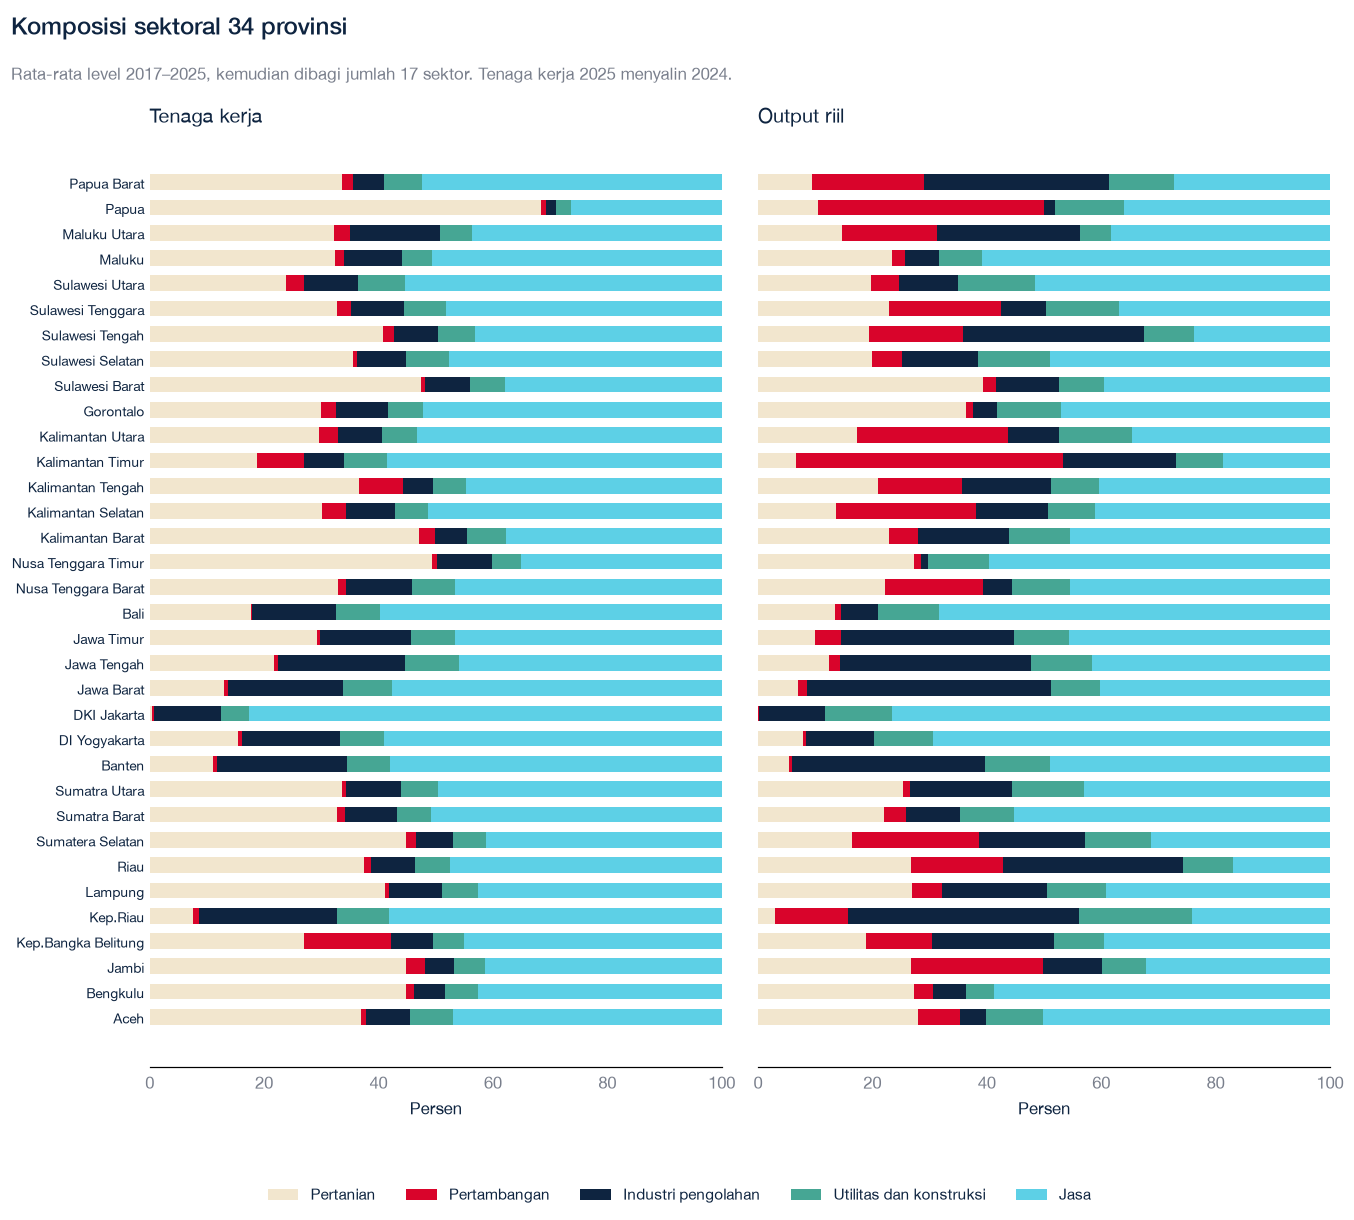

In [7]:
level_tk = src.groupby(["Code_Prov", "Pre_Prov", "Pulau"], as_index=False)[list(tk.values())].mean()
level_y = src.groupby("Code_Prov", as_index=False)[list(yk.values())].mean()
prov = pd.concat([
    level_tk[["Pre_Prov", "Pulau"]],
    shares_from_levels(level_tk, tk).add_prefix("tk_"),
    shares_from_levels(level_y, yk).add_prefix("y_"),
], axis=1)
prov["ord"] = prov.Pulau.map({p: i for i, p in enumerate(ISLANDS)})
prov = prov.sort_values(["ord", "Pre_Prov"])

fig, axes = plt.subplots(1, 2, figsize=(12.4, 11.2), sharey=True)
stacked(axes[0], prov, "tk_", "Tenaga kerja")
stacked(axes[1], prov, "y_", "Output riil")
axes[0].set_yticklabels(prov.Pre_Prov, fontsize=9)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=5, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, 0.02))
head(fig, "Komposisi sektoral 34 provinsi",
     "Rata-rata level 2017–2025, kemudian dibagi jumlah 17 sektor. Tenaga kerja 2025 menyalin 2024.", top=0.90)
fig.tight_layout(rect=(0, 0.05, 1, 0.90))
save(fig, "A1_komposisi_34_provinsi.png")


--> Lampiran. Urutan mengikuti wilayah. Pangsa memakai rata-rata level 2017–2025.
